# 04 — Schwellenwert-Optimierung + Hyperparameter-Suche

Schwellenwert-Tuning für beide bereits trainierten Modelle (kein Retraining nötig) sowie eine Hyperparameter-Suche für den Random Forest, bewertet anhand der über alle vier Labels gemittelten PR-AUC.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import pickle
import json
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit
from sklearn.metrics import average_precision_score

from src.paths import figure_path, result_path
from src.data import TARGET_COLUMNS, FEATURE_COLUMNS, ENCODED_TYPE_COLUMNS
from src.train import find_optimal_thresholds_multilabel, evaluate_sklearn_classifier, _metrics_per_label

## 1. Schwellenwert-Optimierung für MLP und Random Forest

Auf dem Validierungsset bestimmt -- nicht dem Testset, um Data Leakage zu vermeiden.

In [2]:
# Val-Wahrscheinlichkeiten aus Notebook 02 (MLP) und 03 (RF) laden
mlp_val = np.load("../data/processed/mlp_val_probs.npz")
rf_val = np.load("../data/processed/rf_val_probs.npz")

# Pro Modell UND pro Label einen eigenen F1-optimalen Schwellenwert bestimmen
mlp_thresholds = find_optimal_thresholds_multilabel(mlp_val["y_true"], mlp_val["y_prob"])
rf_thresholds = find_optimal_thresholds_multilabel(rf_val["y_true"], rf_val["y_prob"])

for col in TARGET_COLUMNS:
    mt, mf1 = mlp_thresholds[col]
    rt, rf1 = rf_thresholds[col]
    print(f"{col:<6} MLP: Schwelle={mt:.3f} F1(val)={mf1:.3f}   RF: Schwelle={rt:.3f} F1(val)={rf1:.3f}")

TWF    MLP: Schwelle=0.935 F1(val)=0.250   RF: Schwelle=0.273 F1(val)=0.250
HDF    MLP: Schwelle=0.957 F1(val)=0.903   RF: Schwelle=0.427 F1(val)=0.971
PWF    MLP: Schwelle=0.983 F1(val)=0.833   RF: Schwelle=0.513 F1(val)=1.000
OSF    MLP: Schwelle=0.958 F1(val)=0.933   RF: Schwelle=0.373 F1(val)=0.903


## 2. Testset-Ergebnisse mit den optimierten Schwellenwerten

In [3]:
# Testset-Wahrscheinlichkeiten laden und die zuvor auf dem Val-Set
# gefundenen Schwellenwerte anwenden (nicht neu auf dem Testset suchen!)
mlp_test = np.load("../data/processed/mlp_test_probs.npz")
rf_test = np.load("../data/processed/rf_test_probs.npz")

mlp_test_thresh = [mlp_thresholds[col][0] for col in TARGET_COLUMNS]
rf_test_thresh = [rf_thresholds[col][0] for col in TARGET_COLUMNS]

mlp_metrics_opt, mlp_cm_opt = _metrics_per_label(mlp_test["y_true"], mlp_test["y_prob"], mlp_test_thresh, TARGET_COLUMNS)
rf_metrics_opt, rf_cm_opt = _metrics_per_label(rf_test["y_true"], rf_test["y_prob"], rf_test_thresh, TARGET_COLUMNS)
print("MLP:"); print(mlp_metrics_opt)
print("\nRF:"); print(rf_metrics_opt)

MLP:
       threshold  precision    recall        f1   roc_auc    pr_auc  \
label                                                                 
TWF     0.934839   0.000000  0.000000  0.000000  0.919721  0.053811   
HDF     0.957106   1.000000  0.588235  0.740741  0.999683  0.975573   
PWF     0.982898   0.833333  0.714286  0.769231  0.998894  0.878455   
OSF     0.958109   0.928571  0.866667  0.896552  0.999731  0.977632   

       n_positive    tn  fp  fn  tp  
label                                
TWF             7  1478  15   7   0  
HDF            17  1483   0   7  10  
PWF            14  1484   2   4  10  
OSF            15  1484   1   2  13  

RF:
       threshold  precision    recall        f1   roc_auc    pr_auc  \
label                                                                 
TWF     0.273333   0.000000  0.000000  0.000000  0.958712  0.055156   
HDF     0.426667   1.000000  0.941176  0.969697  1.000000  1.000000   
PWF     0.513333   1.000000  1.000000  1.000000  1.

## 3. Hyperparameter-Suche für Random Forest

`RandomizedSearchCV` mit eigenem Scorer (gemittelte PR-AUC über alle vier Labels), `PredefinedSplit` (Train immer Fold -1, Val immer Fold 0 -- kein zufälliges Neu-Mischen der Validierungsdaten).

In [4]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
feature_cols = FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS

# Train+Val zusammen als Suchraum für RandomizedSearchCV, mit PredefinedSplit
# als fixer Vorgabe, welche Zeilen Training bzw. Validierung sind
X_trainval = pd.concat([train_df, val_df])[feature_cols]
y_trainval = pd.concat([train_df, val_df])[TARGET_COLUMNS].values
test_fold = [-1] * len(train_df) + [0] * len(val_df)
ps = PredefinedSplit(test_fold)

param_dist = {
    "estimator__n_estimators": [100, 200, 300],
    "estimator__max_depth": [10, 20, 30, None],
    "estimator__min_samples_leaf": [1, 2, 3, 5],
    "estimator__max_features": ["sqrt", "log2"],
}

# Eigener Scorer: predict_proba() liefert bei MultiOutputClassifier eine Liste
# von Arrays (eines je Label) -- hier zur mittleren PR-AUC über alle Labels vereint
def mean_pr_auc_multilabel(estimator, X, y):
    proba_list = estimator.predict_proba(X)
    scores = []
    for i in range(y.shape[1]):
        if y[:, i].sum() > 0:
            scores.append(average_precision_score(y[:, i], proba_list[i][:, 1]))
    return float(np.mean(scores))

base_rf = RandomForestClassifier(class_weight="balanced_subsample", random_state=42, n_jobs=-1)
multi_rf = MultiOutputClassifier(base_rf)

search = RandomizedSearchCV(
    multi_rf, param_dist, n_iter=15, scoring=mean_pr_auc_multilabel,
    cv=ps, random_state=42, n_jobs=-1,
)
search.fit(X_trainval, y_trainval)
print("Beste Hyperparameter:", search.best_params_)
print(f"Beste gemittelte PR-AUC (Validierung): {search.best_score_:.3f}")

Beste Hyperparameter: {'estimator__n_estimators': 300, 'estimator__min_samples_leaf': 2, 'estimator__max_features': 'sqrt', 'estimator__max_depth': None}
Beste gemittelte PR-AUC (Validierung): 0.793


## 4. Finales getuntes Modell + erneute Schwellenwert-Optimierung

Da sich das Vorhersageverhalten durch das Tuning verändert, wird der Schwellenwert danach erneut bestimmt.

In [5]:
# estimator__-Präfix (durch MultiOutputClassifier-Wrapper) entfernen,
# um die Parameter direkt an RandomForestClassifier übergeben zu können
best_params = {k.replace("estimator__", ""): v for k, v in search.best_params_.items()}
tuned_rf = MultiOutputClassifier(
    RandomForestClassifier(**best_params, class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    n_jobs=-1,
)
# Bewusst nur auf Train (nicht Train+Val) neu fitten, damit Val weiterhin
# für die nachfolgende Schwellenwert-Re-Optimierung zur Verfügung steht
X_train = train_df[feature_cols]
y_train = train_df[TARGET_COLUMNS].values
tuned_rf.fit(X_train, y_train)

X_val = val_df[feature_cols]
y_val = val_df[TARGET_COLUMNS].values
tuned_val_result = evaluate_sklearn_classifier(tuned_rf, X_val, y_val, threshold=0.5)
tuned_thresholds = find_optimal_thresholds_multilabel(tuned_val_result["y_true"], tuned_val_result["y_prob"])

test_df = pd.read_csv("../data/processed/test.csv")
X_test = test_df[feature_cols]
y_test = test_df[TARGET_COLUMNS].values
tuned_test_thresh = [tuned_thresholds[col][0] for col in TARGET_COLUMNS]
tuned_test_result = evaluate_sklearn_classifier(tuned_rf, X_test, y_test, threshold=tuned_test_thresh)
tuned_test_result["metrics"]

,threshold,precision,recall,f1,roc_auc,pr_auc,n_positive,tn,fp,fn,tp
label,,,,,,,,,,,
TWF,0.245459,0.000000,0.000000,0.000000,0.959717,0.058891,7,1487,6,7,0
HDF,0.622190,1.000000,0.941176,0.969697,1.000000,1.000000,17,1483,0,1,16
PWF,0.532710,1.000000,1.000000,1.000000,1.000000,1.000000,14,1486,0,0,14
OSF,0.481037,0.785714,0.733333,0.758621,0.998339,0.890397,15,1482,3,4,11


Ein einzelner Baum aus dem getunten Wald für HDF, zur Veranschaulichung der Splits.


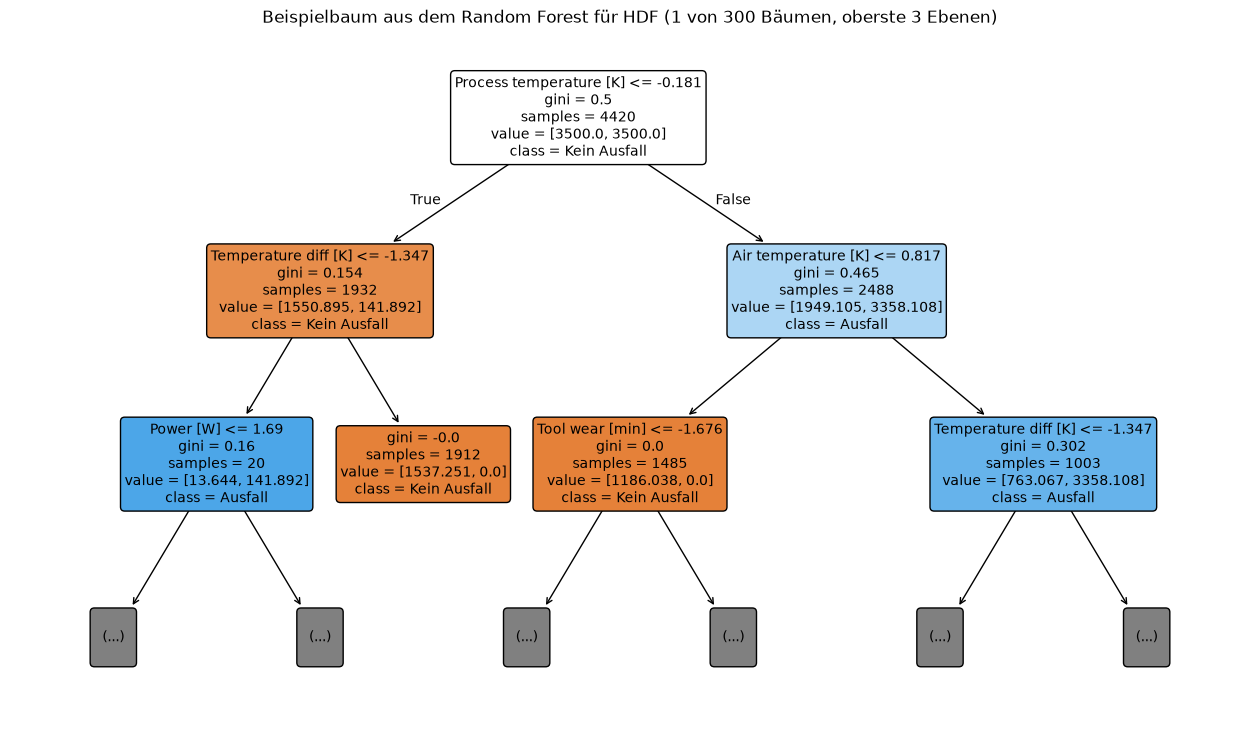

Tiefe 11, Blätter 20
Zweiter Split: Temperature diff [K] <= -1.347 (standardisiert) = 8.65 in Originaleinheiten


In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Baum 0 aus dem getunten Wald für HDF, dargestellt auf die obersten drei Ebenen begrenzt
hdf_tree = tuned_rf.estimators_[TARGET_COLUMNS.index("HDF")].estimators_[0]
fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(hdf_tree, max_depth=2, feature_names=FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS,
          class_names=["Kein Ausfall", "Ausfall"], filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f"Beispielbaum aus dem Random Forest für HDF (1 von {tuned_rf.estimators_[0].n_estimators} Bäumen, oberste 3 Ebenen)", fontsize=12)
plt.savefig(figure_path("tree", "example_tree.png"), dpi=150, bbox_inches="tight")
plt.show()

# Tiefe und Blattzahl des vollständigen Baums; Schwelle des zweiten Splits in Originaleinheiten
with open("../models/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)
tree = hdf_tree.tree_
node = tree.children_left[0]
feature = (FEATURE_COLUMNS + ENCODED_TYPE_COLUMNS)[tree.feature[node]]
j = list(scaler.feature_names_in_).index(feature)
threshold_original = tree.threshold[node] * scaler.scale_[j] + scaler.mean_[j]
print(f"Tiefe {hdf_tree.get_depth()}, Blätter {hdf_tree.get_n_leaves()}")
print(f"Zweiter Split: {feature} <= {tree.threshold[node]:.3f} (standardisiert) = {threshold_original:.2f} in Originaleinheiten")

## 5. Alles speichern

In [7]:
with open("../models/random_forest_multilabel_tuned.pkl", "wb") as f:
    pickle.dump(tuned_rf, f)

thresholds_out = {
    "MLP-MultiLabel": {col: mlp_thresholds[col][0] for col in TARGET_COLUMNS},
    "Random-Forest-MultiLabel": {col: rf_thresholds[col][0] for col in TARGET_COLUMNS},
    "Random-Forest-MultiLabel-getunt": {col: tuned_thresholds[col][0] for col in TARGET_COLUMNS},
}
with open("../models/optimal_thresholds_multilabel.json", "w") as f:
    json.dump(thresholds_out, f, indent=2)

mlp_metrics_opt.to_csv(result_path("tuning", "mlp_metrics_threshold_optimized.csv"))
rf_metrics_opt.to_csv(result_path("tuning", "rf_metrics_threshold_optimized.csv"))
tuned_test_result["metrics"].to_csv(result_path("tuning", "rf_tuned_metrics.csv"))

# Getunte RF-Wahrscheinlichkeiten separat speichern (wurden bisher NICHT
# persistiert -- Notebook 05 hätte sonst versehentlich die UNGETUNTEN
# Wahrscheinlichkeiten mit den GETUNTEN Schwellenwerten kombiniert)
np.savez("../data/processed/rf_tuned_test_probs.npz",
         y_true=tuned_test_result["y_true"], y_prob=tuned_test_result["y_prob"])
print("Gespeichert.")

Gespeichert.
